# PeakPilot — machine-learning studies (SciPy and MATLAB)

Spec: [`.kiro/specs/ml-models/`](../.kiro/specs/ml-models/) · Studies: `s1_thermal_id.py`, `s2_forecast_value.py`, `s3_matlab_parity.m`, `s4_solar_mppt.py`

**Everything in this notebook is SIMULATED.** The PeakPilot engine generates the telemetry; seeded noise
stands in for sensor error; Study 2's multi-day history is synthetic. The studies ask *where a learned model
could help PeakPilot and by how much*, and they make no real-world accuracy, cost or emissions claim.

| Study | Question | Tools |
|---|---|---|
| S1 | Can a model fitted to thermostat-style data recover the room thermal model, and does it matter? | SciPy `linalg.lstsq`, `optimize.least_squares` |
| S2 | How much peak could a load forecast save, and how fast does forecast error eat it? | SciPy `linalg`, existing LP (`peakpilot.optimal`) |
| S3 | Do the same fits give the same answers in MATLAB, and can MATLAB drive the engine? | MATLAB R2026b `mldivide`, `lsqnonlin`, `pyenv` |
| S4 | How well does the rooftop PV's MPPT track, and what is PV worth to the peak? | engine PV model, SciPy `optimize.minimize_scalar`, LP |

Re-run from the repo root: `pip install -r studies/requirements.txt`, then run all cells with `studies/` as the working directory.
S3 needs MATLAB; without it the notebook shows the saved MATLAB results.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STUDIES = Path.cwd()
sys.path.insert(0, str(STUDIES))
sys.path.insert(0, str(STUDIES.parent))  # repo root

import s1_thermal_id as s1
import s2_forecast_value as s2
import s4_solar_mppt as s4
from peakpilot import engine, scenarios

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## S1 — learn the room thermal model

The engine's room model is linear in its two parameters, so it is a regression problem:

$$T_{t+1} = T_t + a\,(T^{out}_t - T_t) - b\,u_t,\qquad a = \tfrac{1}{RC},\; b = \tfrac{\eta}{C}$$

* **EE (equation error)** — ordinary least squares on one-step differences.
* **OE (output error)** — simulate the whole evening and fit $a, b, T_0$ with nonlinear least squares.

Training data is the coordinated run of *Hot evening* (31 °C peak); the held-out test is a *34 °C* evening.

In [2]:
r1 = s1.main()
rows = pd.DataFrame(r1["rows"])
print(f"true a = {r1['a_true']:.5f}, b = {r1['b_true']:.5f}")
rows.pivot_table(index=["noise_c", "train_min"], columns="method",
                 values=["a_err_pct", "b_err_pct", "test_rmse_c"]).round(3)

true a = 0.06944, b = 0.35556


a_err_pct        b_err_pct        test_rmse_c       
method                   EE     OE        EE     OE          EE     OE
noise_c train_min                                                     
0.00    60           -0.000 -0.000     0.000  0.000       0.000  0.000
        120           0.000  0.000    -0.000 -0.000       0.000  0.000
        240          -0.000 -0.000     0.000  0.000       0.000  0.000
        480          -0.000 -0.000     0.000  0.000       0.000  0.000
        960          -0.000 -0.000    -0.000 -0.000       0.000  0.000
0.05    60           -0.182  0.521    -0.018  0.598       0.012  0.010
        120           0.036  0.470     0.127  0.498       0.007  0.007
        240           0.146  0.227     0.073  0.251       0.005  0.004
        480          -0.106  0.113    -0.152  0.135       0.004  0.002
        960          -0.010  0.090    -0.107  0.114       0.007  0.002
0.10    60            0.606  0.264     0.431  0.231       0.013  0.004
        120           0.486 -0.130     0.293 -0.079       0.014  0.004
        240           0.657 -0.093     0.668 -0.079       0.009  0.001
        480           0.852 -0.047     0.733 -0.012       0.013  0.002
        960           1.199 -0.144     0.897 -0.101       0.024  0.003
0.20    60           -0.922  3.677    -1.728  3.347       0.062  0.049
        120          -0.341  1.848    -0.550  1.906       0.017  0.025
        240          -1.165  0.426    -1.598  0.479       0.038  0.007
        480           0.594  0.420    -0.023  0.438       0.043  0.006
        960           1.914  0.240     0.599  0.275       0.091  0.004

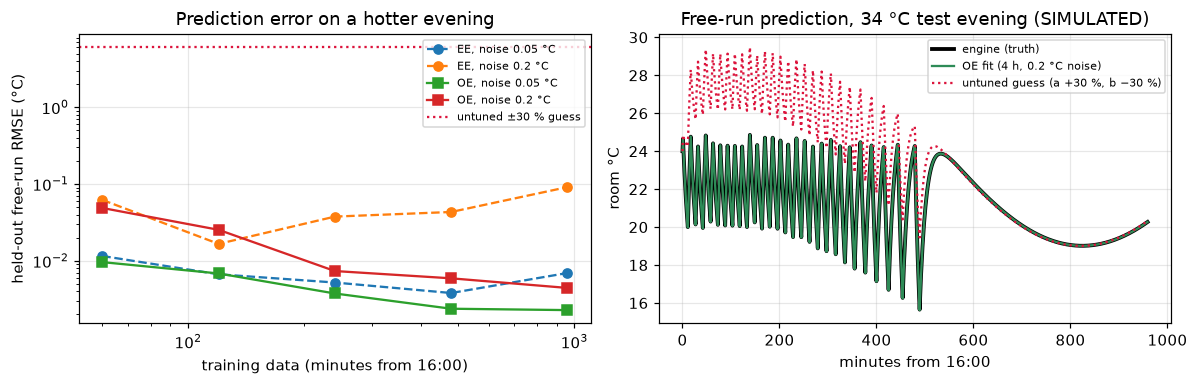

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for method, style in (("EE", "o--"), ("OE", "s-")):
    sub = rows[rows.method == method]
    for sigma in (0.05, 0.2):
        d = sub[sub.noise_c == sigma]
        axes[0].plot(d.train_min, d.test_rmse_c, style, label=f"{method}, noise {sigma} °C")
axes[0].set(xscale="log", yscale="log", xlabel="training data (minutes from 16:00)",
            ylabel="held-out free-run RMSE (°C)", title="Prediction error on a hotter evening")
axes[0].axhline(r1["untuned_guess_worst_test_rmse_c"], color="crimson", ls=":", label="untuned ±30 % guess")
axes[0].legend(fontsize=7)

test_sc = scenarios.custom_scenario(peak_outdoor_c=34.0)
room, out, u = s1.telemetry(test_sc)
oe = rows[(rows.method == "OE") & (rows.noise_c == 0.2) & (rows.train_min == 240)].iloc[0]
t = np.arange(len(room))
axes[1].plot(t, room, lw=2.5, color="black", label="engine (truth)")
axes[1].plot(t, s1.simulate(oe.a, oe.b, room[0], out, u), color="seagreen", label="OE fit (4 h, 0.2 °C noise)")
a0, b0 = r1["a_true"] * 1.3, r1["b_true"] * 0.7
axes[1].plot(t, s1.simulate(a0, b0, room[0], out, u), color="crimson", ls=":", label="untuned guess (a +30 %, b −30 %)")
axes[1].set(xlabel="minutes from 16:00", ylabel="room °C", title="Free-run prediction, 34 °C test evening (SIMULATED)")
axes[1].legend(fontsize=7)
plt.tight_layout()

In [4]:
lp = pd.Series(r1["lp_bound_kw_by_model"], name="LP lower bound (kW)")
print("Perfect-foresight LP bound on the 34 °C evening, by room model:")
lp.round(3).to_frame().assign(shift_pct=lambda d: (100 * (d.iloc[:, 0] / lp["true"] - 1)).round(1))

Perfect-foresight LP bound on the 34 °C evening, by room model:


,LP lower bound (kW),shift_pct
true,6.285,-0.0
fitted_oe,6.285,-0.0
guess_0,6.284,-0.0
guess_1,5.976,-4.9
guess_2,7.298,16.1
guess_3,6.286,0.0


**S1 findings.** Both methods recover $a, b$ to within 2 % with as little as 2–4 h of data, even at 0.2 °C sensor
noise. OE is the better predictor (test RMSE ≈ 0.004–0.007 °C vs 0.04–0.09 °C for EE at 0.2 °C noise) because it
does not regress on noisy readings. An untuned model that is 30 % off drifts by up to 6 °C and moves the LP benchmark's
lower bound by −5 % to +16 %; the fitted model reproduces it exactly. **Benefit:** calibration makes the room model —
and every number the "How close to optimal?" panel shows — trustworthy for a *specific* building. It does not change
the reactive controller, which only reads the thermostat.

## S2 — what is a load forecast worth?

The reactive scheduler sees only the current minute; the LP sees the whole evening. Part A measures the space
between them and plays LP plans built on *wrong* forecasts against the true evening. Part B trains three day-ahead
forecasters on a seeded synthetic history and does the same over 30 held-out evenings.

In [5]:
r2 = s2.main()
a = r2["part_a"]
cases = pd.DataFrame(a["cases"]).set_index("case")[["base_mae_kw", "planned_peak_kw", "realized_peak_kw", "comfort_violation_min"]]
print(f"Reactive floor (lowest limit PeakPilot holds with all work done): {a['reactive_floor_limit_kw']} kW")
print(f"Perfect-foresight bound: {a['perfect_bound_kw']:.2f} kW")
cases

Reactive floor (lowest limit PeakPilot holds with all work done): 7.8 kW
Perfect-foresight bound: 6.03 kW


,base_mae_kw,planned_peak_kw,realized_peak_kw,comfort_violation_min
case,,,,
perfect,0.000,6.028,6.028,0
base x0.9,0.299,5.726,6.147,0
base x1.1,0.299,6.330,6.081,0
base x1.2,0.597,6.631,6.134,0
base 30 min early,0.119,6.021,6.353,0
base 60 min early,0.225,6.002,6.652,0
base 30 min late,0.121,6.029,6.378,0
base 60 min late,0.238,6.028,6.712,0
base noise 0.2 kW,0.160,6.024,6.791,0


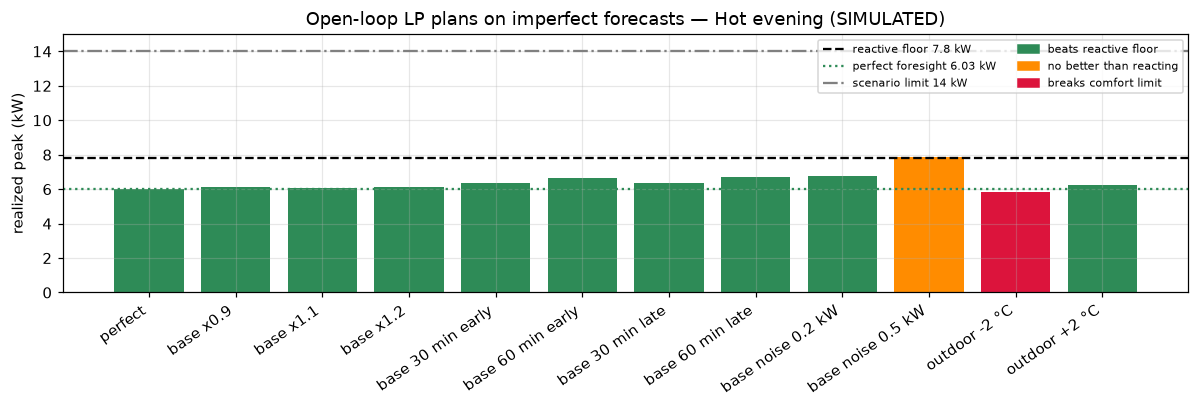

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
c = cases.realized_peak_kw
colors = ["crimson" if v > 0 else ("seagreen" if p <= a["reactive_floor_limit_kw"] else "darkorange")
          for p, v in zip(c, cases.comfort_violation_min)]
ax.bar(c.index, c.values, color=colors)
ax.axhline(a["reactive_floor_limit_kw"], color="black", ls="--", label=f"reactive floor {a['reactive_floor_limit_kw']} kW")
ax.axhline(a["perfect_bound_kw"], color="seagreen", ls=":", label=f"perfect foresight {a['perfect_bound_kw']:.2f} kW")
ax.axhline(14.0, color="grey", ls="-.", label="scenario limit 14 kW")
ax.set(ylabel="realized peak (kW)", title="Open-loop LP plans on imperfect forecasts — Hot evening (SIMULATED)", ylim=(0, 15))
ax.tick_params(axis="x", rotation=35)
for lbl in ax.get_xticklabels():
    lbl.set_ha("right")
from matplotlib.patches import Patch
handles, _ = ax.get_legend_handles_labels()
handles += [Patch(color="seagreen", label="beats reactive floor"),
            Patch(color="darkorange", label="no better than reacting"),
            Patch(color="crimson", label="breaks comfort limit")]
ax.legend(handles=handles, fontsize=7, ncol=2)
plt.tight_layout()

In [7]:
b = r2["part_b"]
print(f"Mean perfect-foresight bound over {b['test_days']} synthetic test evenings: {b['perfect_bound_mean_kw']:.2f} kW")
pd.DataFrame(b["models"]).T

Mean perfect-foresight bound over 30 synthetic test evenings: 5.71 kW


,mae_kw,mean_excess_peak_kw,p90_excess_peak_kw,comfort_violation_days
persistence (yesterday),0.413,0.688,0.834,0.0
climatology (mean day),0.366,0.487,0.552,0.0
ridge on outdoor peak,0.141,0.455,0.542,0.0


**S2 findings.**

* **The real headroom is 1.8 kW, not 8 kW.** The dashboard's optimal panel compares the LP with a run capped at the
  *chosen* 14 kW limit, so it shows a 7.97 kW (57 %) gap. The reactive scheduler can actually hold **7.8 kW** with every
  deadline and the comfort limit met; perfect foresight reaches **6.03 kW**. Showing the reactive floor beside the
  bound answers the Kiro dashboard review's item 8 without any ML.
* **Forecast quality decides whether planning beats reacting.** Scale errors of ±10–20 % cost little (realized peak
  6.1 kW): the LP flattens the device load, so a uniform error mostly shifts it. *Timing* and *noise* errors hurt more
  (6.4–6.8 kW). At 0.5 kW noise the open-loop plan (7.9 kW) is no better than reacting.
* **Under-forecasting heat is the dangerous error.** An outdoor forecast 2 °C too cool makes the plan under-cool and
  breaks the comfort limit for 462 minutes. A deployable planner would need the reactive engine as a safety layer.
* **A learned forecast beats naive ones, modestly.** On the synthetic history, ridge regression on the day's outdoor
  peak cuts forecast MAE 2.6× vs persistence and keeps realized peaks within 0.45 kW of perfect foresight on average,
  vs 0.69 kW for persistence. The relationship was planted by the generator, so this is a pipeline check, not evidence.

## S3 — the same studies in MATLAB R2026b

`s3_matlab_parity.m` repeats S1 (`mldivide`, `lsqnonlin`) and S2's ridge fit on the CSVs the Python studies wrote,
then calls `peakpilot.engine.compare()` from MATLAB through `pyenv` (out-of-process, the project's Python 3.12).
Only base MATLAB and the Optimization Toolbox are used. The cell below re-runs MATLAB if it is on this machine,
otherwise it shows the saved results.

In [8]:
import os, shutil, subprocess
matlab = shutil.which("matlab") or "/Applications/MATLAB_R2026b.app/bin/matlab"
if Path(matlab).exists():
    env = dict(os.environ, PEAKPILOT_PYTHON=os.environ.get("PEAKPILOT_PYTHON", sys.executable))
    subprocess.run([matlab, "-batch", "s3_matlab_parity"], cwd=STUDIES, env=env,
                   check=True, capture_output=True, timeout=600)
else:
    print("MATLAB not found; showing saved results/s3_matlab_parity.json")
r3 = json.loads((STUDIES / "results" / "s3_matlab_parity.json").read_text())
th, fc, io = r3["thermal"], r3["forecast"], r3["interop"]
pd.DataFrame([
    ["thermal EE a, b", f"{th['ee_a']:.6f}, {th['ee_b']:.6f}", f"{th['scipy_ee_a']:.6f}, {th['scipy_ee_b']:.6f}", th["max_abs_diff_ee"]],
    ["thermal OE a, b", f"{th['oe_a']:.6f}, {th['oe_b']:.6f}", f"{th['scipy_oe_a']:.6f}, {th['scipy_oe_b']:.6f}", th["max_abs_diff_oe"]],
    ["ridge test MAE kW", f"{fc['ridge_test_mae_kw']:.6f}", f"{fc['scipy_ridge_test_mae_kw']:.6f}", fc["abs_diff_kw"]],
    ["engine via pyenv: room °C", f"peak {io.get('coordinated_peak_kw')} kW", "CSV truth", io.get("max_abs_diff_room_vs_csv_c")],
], columns=["quantity", "MATLAB " + r3["matlab_release"], "SciPy", "max |diff|"])

,quantity,MATLAB 2026b,SciPy,max |diff|
0,"thermal EE a, b","0.070277, 0.358744","0.070277, 0.358744",5.299e-09
1,"thermal OE a, b","0.069344, 0.355196","0.069344, 0.355196",1.284e-09
2,ridge test MAE kW,0.140880,0.140880,7.997e-08
3,engine via pyenv: room °C,peak 14 kW,CSV truth,4.999e-07


**S3 findings.** MATLAB and SciPy agree to about 1e-8 on every fitted quantity, and MATLAB can drive the real,
stdlib-only engine directly (≈0.1 s per run). MATLAB adds nothing the SciPy path cannot do for these linear models,
and the installed licence lacks the Statistics/ML, System Identification and Deep Learning toolboxes. It costs judges a
licence if used at runtime. **Recommendation:** SciPy for anything that ships; MATLAB as an optional, documented
cross-check (and later for Coder-generated C on an edge device), never on the judge's path.

## Where ML helps PeakPilot — ranked

| # | Use | Benefit seen in the studies | Fits the steering? |
|---|---|---|---|
| 1 | Show the **reactive floor** beside the LP bound (no ML) | headroom reads 1.8 kW, not 8 kW | yes |
| 2 | **Thermal calibration** (OE fit, SciPy) | LP bound and room model correct to < 1 %; bad guess moves the bound up to 16 % | yes — analysis, not control |
| 3 | **Forecast sensitivity** panel ("what if the forecast is off?") | shows timing/noise and cool-bias errors are what matter | yes — analysis |
| 4 | Learned forecast **driving control** | 1.0–1.7 kW below the 7.8 kW reactive floor with forecast errors up to ±20 % scale, ±60 min or 0.2 kW noise; none at 0.5 kW noise | no — needs a steering change (ML-based control is out of scope) |

## S4 — rooftop PV with MPPT

The engine's optional rooftop array (issue #33) is an ideal single-diode string,
$I(V) = I_{sc}\,\bigl(1 - e^{(V - V_{oc})/a}\bigr)$, with $I_{sc}$ scaled by irradiance and
$I_{sc}$, $V_{oc}$, $a$ shifted by cell temperature (NOCT model). Each minute the inverter runs
**perturb and observe**: step the array voltage, keep going while power rises, reverse when it falls.
The engine also finds the true maximum power point by golden-section search, so tracking is measurable.
The scheduler then holds **net grid import** (loads − PV) under the limit.

Part A sweeps the tracker's step size and perturbations per minute, cross-checks the golden-section MPP
against SciPy, and adds a fixed cloud-edge pattern. Part B scales the array on the tight 11 kW workload
and measures the uncoordinated peak, the scheduler's reactive floor and the LP bound. Irradiance is an
illustrative clear-sky curve, not weather data.

In [2]:
r4 = s4.main()
a4 = r4["part_a"]
d = a4["default"]
print(f"default tracker (step {d['step_v']} V, {d['iterations']}/min): efficiency {d['tracking_efficiency']:.5f}, "
      f"{d['pv_kwh']:.2f} kWh, peak {d['peak_pv_kw']:.2f} kW over {d['sunlit_min']} sunlit min")
print(f"golden-section vs SciPy minimize_scalar MPP, max relative diff: {a4['scipy_mpp_max_rel_diff']:.1e}")
sweep = pd.DataFrame(a4["sweep"]).pivot_table(index="step_v", columns="iterations", values="tracking_efficiency")
sweep.columns = [f"{c} per min" for c in sweep.columns]
(sweep * 100).round(3).rename_axis("step (V)")

default tracker (step 2.0 V, 20/min): efficiency 0.99974, 9.63 kWh, peak 3.40 kW over 424 sunlit min
golden-section vs SciPy minimize_scalar MPP, max relative diff: 6.0e-16


,1 per min,5 per min,20 per min
step (V),,,
0.5,98.767,99.933,99.992
1.0,99.681,99.965,99.991
2.0,99.838,99.966,99.974
5.0,99.784,99.878,99.910
10.0,99.417,99.516,99.799


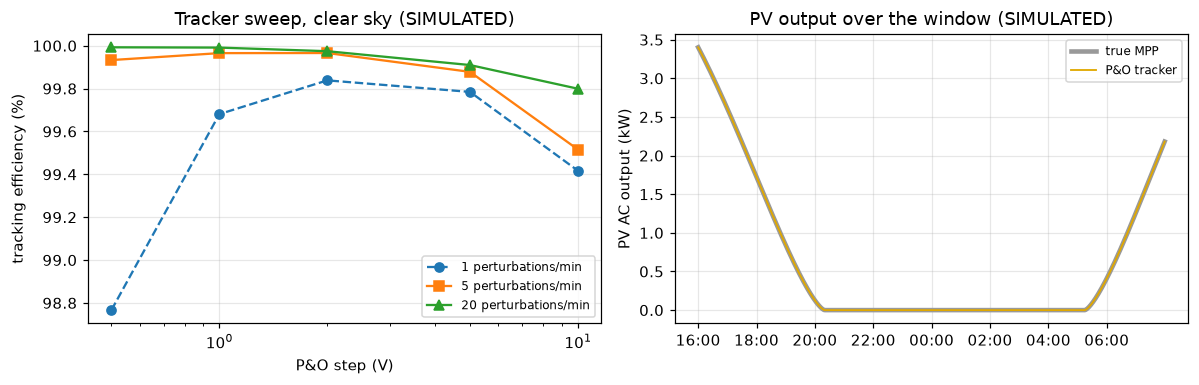

cloud-edge pattern: 1/min 99.58%, 5/min 99.95%, 20/min 99.98%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for iters, style in ((1, "o--"), (5, "s-"), (20, "^-")):
    sub = pd.DataFrame(a4["sweep"]).query("iterations == @iters")
    axes[0].plot(sub.step_v, 100 * sub.tracking_efficiency, style, label=f"{iters} perturbations/min")
clouds = pd.DataFrame(a4["clouds"])
axes[0].set_xscale("log"); axes[0].set_xlabel("P&O step (V)"); axes[0].set_ylabel("tracking efficiency (%)")
axes[0].set_title("Tracker sweep, clear sky (SIMULATED)"); axes[0].legend(fontsize=8)
tr = a4["trace"]
clock = [engine.clock(m) for m in range(engine.WINDOW_MINUTES)]
axes[1].plot(clock, tr["mpp_kw"], color="0.6", lw=3, label="true MPP")
axes[1].plot(clock, tr["pv_kw"], color="#e0a800", lw=1.2, label="P&O tracker")
axes[1].set_xticks(clock[::120]); axes[1].set_ylabel("PV AC output (kW)")
axes[1].set_title("PV output over the window (SIMULATED)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("cloud-edge pattern:", ", ".join(f"{r.iterations}/min {100 * r.tracking_efficiency:.2f}%" for r in clouds.itertuples()))

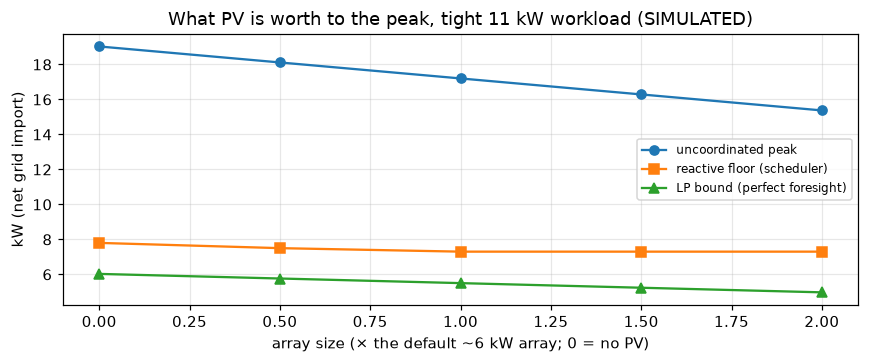

,pv_kwh,task_kwh,uncoordinated_peak_kw,coordinated_peak_kw,reactive_floor_kw,lp_bound_kw,coordinated_all_met
scale,,,,,,,
0.0,0.000,39.0,19.028,11.0,7.8,6.028,True
0.5,4.815,39.0,18.114,11.0,7.5,5.764,True
1.0,9.629,39.0,17.200,11.0,7.3,5.501,True
1.5,14.444,39.0,16.286,11.0,7.3,5.237,True
2.0,19.258,39.0,15.372,11.0,7.3,4.974,True


In [4]:
b4 = pd.DataFrame(r4["part_b"]["rows"]).set_index("scale")
cols = ["pv_kwh", "task_kwh", "uncoordinated_peak_kw", "coordinated_peak_kw", "reactive_floor_kw", "lp_bound_kw", "coordinated_all_met"]
fig, ax = plt.subplots(figsize=(8, 3.4))
for col, style, label in (("uncoordinated_peak_kw", "o-", "uncoordinated peak"),
                          ("reactive_floor_kw", "s-", "reactive floor (scheduler)"),
                          ("lp_bound_kw", "^-", "LP bound (perfect foresight)")):
    ax.plot(b4.index, b4[col], style, label=label)
ax.set_xlabel("array size (× the default ~6 kW array; 0 = no PV)"); ax.set_ylabel("kW (net grid import)")
ax.set_title("What PV is worth to the peak, tight 11 kW workload (SIMULATED)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
b4[cols]

**S4 findings.**

* **The tracker is close to ideal.** Perturb and observe at 2 V and 20 perturbations a minute captures 99.97 % of
  the true-MPP energy (9.6 kWh over 424 sunlit minutes). Small steps need many perturbations to keep up as the sun
  moves (0.5 V at 1/min: 98.8 %); large steps oscillate around the peak (10 V tops out at 99.8 %). A fixed cloud-edge
  pattern costs under 0.1 point at 20/min. The engine's golden-section MPP matches SciPy's `minimize_scalar` to 6e-16.
* **PV lowers the uncoordinated peak almost one-for-one**, 19.0 → 15.4 kW from no PV to a 2× array, because that
  peak is at 16:00 when the sun is strong.
* **The reactive scheduler gains 0.5 kW, then stops.** Its floor falls from 7.8 to 7.3 kW with the default array and
  not at all beyond it: the minutes that bind it come after the 20:20 sunset, and a scheduler that sees only the
  current minute cannot move work into the sunny hours.
* **Foresight keeps gaining.** The LP bound falls about 0.26 kW per half-array (6.03 → 4.97 kW), so the gap between
  the reactive floor and the bound widens from 1.8 to 2.3 kW. PV makes forecast-aware scheduling (ranked #4 above,
  out of scope for control today) more valuable.
* Every case does the same 39 kWh of EV and water-heater work, meets every deadline and holds comfort. Irradiance is
  clear-sky and SIMULATED; nothing here supports a cost or emissions claim.